<a href="https://colab.research.google.com/github/mmariannaholanda/ia_identificacao_tumores/blob/main/treino_redeneural_ia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
# etapa 1 - importar banco de dados e bibliotecas
import pandas as pd
import numpy as np

np.random.seed(42) # *semente* fixa o ponto de partida do sorteador pra que toda vida tenha a mesma sequencia

dados = pd.read_csv("tumores.csv")


#print(dados.head())
# dados.head() = mostra as 5 primeiras linhas da tabela por padrão.

print(dados.shape)
# shape = retorna as dimensões da tabela; primeiro valor = quantidade de linhas; segundo valor = quantidade de colunas.

(569, 6)


In [22]:
# separando teste de treino
# uso pandas para filtrar a tabela original e criar outras para criar 2 tabelas diferentes
treino = dados[dados.iloc[:, 5] == "treino"]
# iloc[:, 5] = seleciona todas as linhas da 6ª coluna; == "treino" = filtra apenas as linhas com esse valor; treino = armazena a tabela filtrada.

teste = dados[dados.iloc[:, 5] == "teste"]
# == "teste" = filtra apenas as linhas com esse valor; teste = armazena a tabela filtrada.


print(treino.shape)
print(teste.shape)
print(treino.head())
print(teste.head())




(455, 6)
(114, 6)
   raio_medio  textura_media  suavidade_media  pontos_concavos_medio  \
0       17.99          10.38          0.11840                 0.1471   
2       19.69          21.25          0.10960                 0.1279   
3       11.42          20.38          0.14250                 0.1052   
4       20.29          14.34          0.10030                 0.1043   
6       18.25          19.98          0.09463                 0.0740   

   B_maligno conjunto  
0          1   treino  
2          1   treino  
3          1   treino  
4          1   treino  
6          1   treino  
    raio_medio  textura_media  suavidade_media  pontos_concavos_medio  \
1        20.57          17.77          0.08474                0.07017   
5        12.45          15.70          0.12780                0.08089   
10       16.02          23.24          0.08206                0.03323   
13       15.85          23.95          0.08401                0.05364   
15       14.54          27.54          0

In [23]:
# pre processamento de dados em ML
# fazer com que as 4 características dos tumores tenham escalas comparáveis


# criando series do pandas
media = treino.iloc[:, 0:4].mean()
# mean() = calcula a média de cada coluna; iloc[:, 0:4] = seleciona todas as linhas e as 4 primeiras colunas.
desvio = treino.iloc[:, 0:4].std()
# std() = calcula o desvio padrão de cada coluna usando os dados de treino.


# Standardization
treino_padronizado = (treino.iloc[:, 0:4] - media) / desvio
teste_padronizado = (teste.iloc[:, 0:4] - media) / desvio


# baseline
# temos as classes benigno e maligno, vamos ver qual aparece mais
print(treino["B_maligno"].value_counts())
classe_majoritaria = treino["B_maligno"].mode()[0]
# mode() = encontra o valor que mais aparece na coluna; [0] = acessa a primeira moda encontrada; classe_majoritaria = armazena esse valor.
previsoes = [classe_majoritaria] * len(teste)
# [classe_majoritaria] = cria uma lista com a classe 0; len(teste) = quantidade de registros de teste; * = repete a classe 0 para todos os registros.
from sklearn.metrics import accuracy_score  # Importa accuracy_score, função que calcula a proporção de previsões corretas.
baseline = accuracy_score(teste["B_maligno"], previsoes)  # Compara as classificações reais do teste com as previsões criadas.
print(baseline)  # Exibe a acurácia da baseline.
# ficou igual a 63,2%

B_maligno
0    285
1    170
Name: count, dtype: int64
0.631578947368421


In [24]:
# montando a base de ref da rede
entradas_treino = treino_padronizado[['raio_medio', 'textura_media', 'suavidade_media', 'pontos_concavos_medio']].values
respostas_treino = treino['B_maligno'].values.reshape(-1, 1)   # .vslues transforma em array
# como acessar? X[0][0] a 1- primeira caracteristica 2- primeira linha= xn  y[0] - 1- xn

# o teste usa o mesmo formato (padronizado com a média e o desvio do treino)
entradas_teste = teste_padronizado[['raio_medio', 'textura_media', 'suavidade_media', 'pontos_concavos_medio']].values
respostas_teste = teste['B_maligno'].values.reshape(-1, 1)

# arquitetura
quantidade_entradas = 4
quantidade_neuronios_escondidos = 12
quantidade_neuronios_saida = 1  # ja que e benigno ou maligno

# outras variaveis
taxa_aprendizado = 0.1
quantidade_passos = 5000  # qntd de epocas


# pesos e bias
pesos_escondida = np.random.randn(quantidade_entradas, quantidade_neuronios_escondidos) * np.sqrt(2/quantidade_entradas)
 # pesos_escondida = matriz de pesos da primeira camada;
 # np.random.randn() = gera valores aleatórios com distribuição normal;
 # np.sqrt() = calcula a raiz quadrada; 2/quantidade_entradas = fator de escala He para inicialização dos pesos.

vies_escondida = np.zeros((1, quantidade_neuronios_escondidos))    # 1 bias por neuronio
# np.zeros() = cria uma matriz preenchida com zeros; (1, quantidade_neuronios_escondidos) = define 1 linha e 8 colunas.

pesos_saida = np.random.randn(quantidade_neuronios_escondidos, quantidade_neuronios_saida) * np.sqrt(1/quantidade_neuronios_escondidos)

vies_saida = np.zeros((1, quantidade_neuronios_saida))



# formulas
def relu(x):  # transforma os valores negativos em zero e mantém os positivos
    return np.maximum(0, x)

def sigmoide(x): # transforma o resultado em uma probabilidade entre 0 e 1
    return 1 / (1 + np.exp(-x))


def calcular_perda(respostas, probabilidades):
    epsilon = 1e-7

    probabilidades = np.clip(probabilidades, epsilon, 1-epsilon)

    perda = -np.mean(
        respostas * np.log(probabilidades) +
        (1-respostas) * np.log(1-probabilidades)
    )
    return perda



def propagar(entradas, pesos_escondida, vies_escondida, pesos_saida, vies_saida):

    # @ representa a multiplicação de matrizes
    soma_escondida = entradas @ pesos_escondida + vies_escondida       # Combinação dos pesos e entradas
    ativacao_escondida = relu(soma_escondida)          # Ativação da camada escondida

    soma_saida = ativacao_escondida @ pesos_saida + vies_saida      # Combinação para a saída
    probabilidades = sigmoide(soma_saida)  # Probabilidade final

    return probabilidades, soma_escondida, ativacao_escondida  # devolve o resultado previsto (probabilidades), a soma antes da ReLU e a saida da escondida (ativacao_escondida)


def calcular_gradientes(entradas, respostas, probabilidades, soma_escondida, ativacao_escondida, pesos_saida):

    quantidade_amostras = entradas.shape[0]

    # Gradientes da camada de saída (começa por aqui, de trás para frente)
    erro_saida = (probabilidades - respostas) / quantidade_amostras

    grad_pesos_saida = ativacao_escondida.T @ erro_saida

    grad_vies_saida = np.sum(erro_saida, axis=0, keepdims=True)

    # Gradientes da camada escondida
    grad_ativacao_escondida = erro_saida @ pesos_saida.T

    erro_escondida = grad_ativacao_escondida * (soma_escondida > 0)

    grad_pesos_escondida = entradas.T @ erro_escondida

    grad_vies_escondida = np.sum(erro_escondida, axis=0, keepdims=True)


    return grad_pesos_escondida, grad_vies_escondida, grad_pesos_saida, grad_vies_saida


def atualizar_parametros(pesos_escondida, vies_escondida, pesos_saida, vies_saida,
                         grad_pesos_escondida, grad_vies_escondida, grad_pesos_saida, grad_vies_saida,
                         taxa_aprendizado):

    pesos_escondida = pesos_escondida - taxa_aprendizado * grad_pesos_escondida
    vies_escondida = vies_escondida - taxa_aprendizado * grad_vies_escondida

    pesos_saida = pesos_saida - taxa_aprendizado * grad_pesos_saida
    vies_saida = vies_saida - taxa_aprendizado * grad_vies_saida

    return pesos_escondida, vies_escondida, pesos_saida, vies_saida

dados.info()
# info() = apresenta informações estruturais da tabela, como nomes das colunas, quantidade de valores não nulos e tipos de dados.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   raio_medio             569 non-null    float64
 1   textura_media          569 non-null    float64
 2   suavidade_media        569 non-null    float64
 3   pontos_concavos_medio  569 non-null    float64
 4   B_maligno              569 non-null    int64  
 5   conjunto               569 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 26.8+ KB


In [25]:
# comecando o laco de treino
# etapa final - laço de treino
historico_perda = []   # lista vazia para guardar a perda de cada passo

for passo in range(quantidade_passos):

    # 1) propagar: calcula as probabilidades com os pesos atuais
    probabilidades, soma_escondida, ativacao_escondida = propagar(
        entradas_treino, pesos_escondida, vies_escondida, pesos_saida, vies_saida
    )

    # 2) perda: mede o erro e guarda
    perda = calcular_perda(respostas_treino, probabilidades)
    historico_perda.append(perda)

    # 3) gradientes: quanto mudar cada peso
    (grad_pesos_escondida, grad_vies_escondida,
     grad_pesos_saida, grad_vies_saida) = calcular_gradientes(
        entradas_treino, respostas_treino, probabilidades,
        soma_escondida, ativacao_escondida, pesos_saida
    )

    # 4) atualizar: guarda os novos pesos nas mesmas variáveis
    pesos_escondida, vies_escondida, pesos_saida, vies_saida = atualizar_parametros(
        pesos_escondida, vies_escondida, pesos_saida, vies_saida,
        grad_pesos_escondida, grad_vies_escondida, grad_pesos_saida, grad_vies_saida,
        taxa_aprendizado
    )

    if passo % 100 == 0:
        print(f"passo {passo}: perda = {perda:.4f}")

print(f"perda final: {historico_perda[-1]:.4f}")



passo 0: perda = 0.5247
passo 100: perda = 0.1792
passo 200: perda = 0.1492
passo 300: perda = 0.1416
passo 400: perda = 0.1384
passo 500: perda = 0.1364
passo 600: perda = 0.1349
passo 700: perda = 0.1337
passo 800: perda = 0.1326
passo 900: perda = 0.1315
passo 1000: perda = 0.1303
passo 1100: perda = 0.1291
passo 1200: perda = 0.1282
passo 1300: perda = 0.1274
passo 1400: perda = 0.1267
passo 1500: perda = 0.1261
passo 1600: perda = 0.1256
passo 1700: perda = 0.1251
passo 1800: perda = 0.1244
passo 1900: perda = 0.1238
passo 2000: perda = 0.1232
passo 2100: perda = 0.1226
passo 2200: perda = 0.1221
passo 2300: perda = 0.1215
passo 2400: perda = 0.1210
passo 2500: perda = 0.1206
passo 2600: perda = 0.1201
passo 2700: perda = 0.1198
passo 2800: perda = 0.1194
passo 2900: perda = 0.1192
passo 3000: perda = 0.1189
passo 3100: perda = 0.1186
passo 3200: perda = 0.1184
passo 3300: perda = 0.1182
passo 3400: perda = 0.1179
passo 3500: perda = 0.1177
passo 3600: perda = 0.1175
passo 3700: p

In [26]:
# implementando np.savez
# media e desvio eram do pandas


# vou investigar primeiro
print(media)
print(type(media))
print(media.values)         # array numpy
print(list(media.index))    # lista da array
print("\ndevio:")
print(desvio)
print(desvio.values)        # array numpy
print("\n========================================================================\n") # organizando


# agora que eu vi o que me interessa pro np.savez, vou comecar
np.savez(  # é um zip !!
    "modelo_tumores.npz",  # função do NumPy que salva vários arrays em um único arquivo .npz
    pesos_escondida=pesos_escondida,
    vies_escondida=vies_escondida,
    pesos_saida=pesos_saida,
    vies_saida=vies_saida,
    media=media.values,
    desvio=desvio.values,
    colunas=np.array(list(media.index), dtype=str),
    # 1 array por linha
)
print("modelo salvo ok\n")
print("conferindo...")

modelo = np.load("modelo_tumores.npz")
for nome in modelo.files:
    print(nome, modelo[nome].shape)

    # vai me dizer linhas e colunas
    # media, desvio e colunas serão apenas vetores e o resto matrizes


# dando uma olhada em como ficou cada formato visualmente
print("\n=========================================================================\n")
np.set_printoptions(precision=3, suppress=True, linewidth=150)

modelo = np.load("modelo_tumores.npz")
for nome in modelo.files:
    print("=====", nome, modelo[nome].shape)
    print(modelo[nome])

raio_medio               14.078936
textura_media            19.340440
suavidade_media           0.095838
pontos_concavos_medio     0.048307
dtype: float64
<class 'pandas.core.series.Series'>
[14.079 19.34   0.096  0.048]
['raio_medio', 'textura_media', 'suavidade_media', 'pontos_concavos_medio']

devio:
raio_medio               3.455458
textura_media            4.326244
suavidade_media          0.013825
pontos_concavos_medio    0.039093
dtype: float64
[3.455 4.326 0.014 0.039]


modelo salvo ok

conferindo...
pesos_escondida (4, 12)
vies_escondida (1, 12)
pesos_saida (12, 1)
vies_saida (1, 1)
media (4,)
desvio (4,)
colunas (4,)


===== pesos_escondida (4, 12)
[[ 0.898  0.405  0.407  0.999 -0.413  0.152  1.767  0.371 -1.174  0.02  -0.277 -0.446]
 [ 0.591 -1.219 -1.152  0.207 -0.628  0.463  0.076 -1.047  0.995 -0.369  0.031 -0.952]
 [-0.218  1.294 -0.956  0.736 -0.619  0.434 -0.147  1.323 -0.371 -1.319  0.603 -0.761]
 [ 0.028 -1.819 -0.906  0.59   0.812  0.616  0.095  0.385 -1.09  -0.079

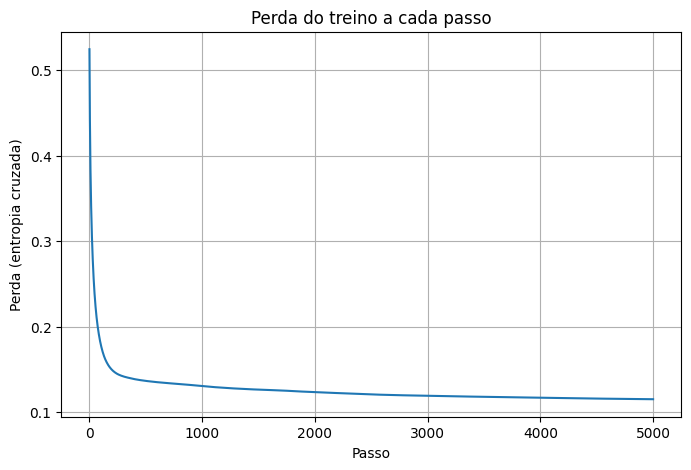

In [27]:
# gráfico da perda
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(historico_perda)
plt.xlabel("Passo")
plt.ylabel("Perda (entropia cruzada)")
plt.title("Perda do treino a cada passo")
plt.grid(True)

plt.savefig("perda_treino.png", dpi=150, bbox_inches="tight")


plt.show()


In [28]:
# acuracia
# transformar cada probabilidade em uma decisao
# COMPARAR COM A DECISAO REAL E GUARDAR QUANTAS VEZES ACERTOU


probabilidades_treino, _, _ = propagar(
    entradas_treino, pesos_escondida, vies_escondida, pesos_saida, vies_saida
)
previsoes_treino = (probabilidades_treino > 0.5).astype(int)   # True vira 1 e False vira 0
acuracia_treino = np.mean(previsoes_treino == respostas_treino)

# no teste (dados que a rede nunca viu)
probabilidades_teste, _, _ = propagar(
    entradas_teste, pesos_escondida, vies_escondida, pesos_saida, vies_saida
)
previsoes_teste = (probabilidades_teste > 0.5).astype(int)
acuracia_teste = np.mean(previsoes_teste == respostas_teste)


acuracia_treino_percentual = acuracia_treino * 100
acuracia_teste_percentual = acuracia_teste * 100
baseline_percentual = baseline * 100

print(f"Acurácia no treino: {acuracia_treino_percentual:.3f} %")
print(f"Acurácia no teste:  {acuracia_teste_percentual:.3f} %")
print(f"Baseline (sempre benigno): {baseline_percentual:.3f} %")
print(f"Ganho sobre o baseline: {acuracia_teste_percentual - baseline_percentual:.3f} pontos")

Acurácia no treino: 95.385 %
Acurácia no teste:  95.614 %
Baseline (sempre benigno): 63.158 %
Ganho sobre o baseline: 32.456 pontos


In [29]:
# aqui eu faço o recall:

verdadeiros_positivos = np.sum((previsoes_teste == 1) & (respostas_teste == 1))
falsos_negativos = np.sum((previsoes_teste == 0) & (respostas_teste == 1))
falsos_positivos = np.sum((previsoes_teste == 1) & (respostas_teste == 0))
verdadeiros_negativos = np.sum((previsoes_teste == 0) & (respostas_teste == 0))

recall_maligno = verdadeiros_positivos / (verdadeiros_positivos + falsos_negativos)

recall_maligno_percentual = recall_maligno * 100

print(f"Verdadeiros positivos: {verdadeiros_positivos}")
print(f"Falsos negativos: {falsos_negativos}")
print(f"Falsos positivos: {falsos_positivos}")
print(f"Verdadeiros negativos: {verdadeiros_negativos}")
print(f"Recall: {recall_maligno_percentual:.3f} %")

Verdadeiros positivos: 41
Falsos negativos: 1
Falsos positivos: 4
Verdadeiros negativos: 68
Recall: 97.619 %


In [30]:
# agora para fazer a matriz de confusão vou usar 4 dados:
# verdadeiros_positivos  e   verdadeiros_negativos
# falsos_negativos  e    falsos_positivos

matriz_confusao = np.array([
    [verdadeiros_negativos, falsos_positivos],
    [falsos_negativos, verdadeiros_positivos]
])

print(matriz_confusao)


[[68  4]
 [ 1 41]]


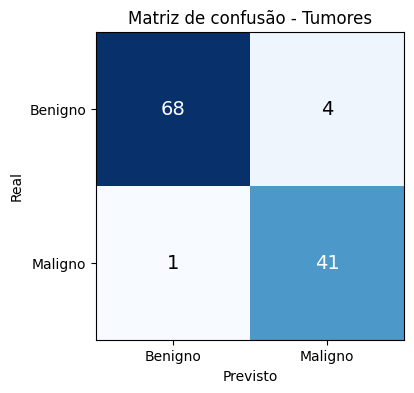

In [31]:
# desenho da matriz de confusão
plt.figure(figsize=(5, 4))
plt.imshow(matriz_confusao, cmap="Blues")

nomes_classes = ["Benigno", "Maligno"]
plt.xticks([0, 1], nomes_classes)
plt.yticks([0, 1], nomes_classes)
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de confusão - Tumores")

# escreve o número dentro de cada quadrado
for linha in range(2):
    for coluna in range(2):

        valor = matriz_confusao[linha, coluna]
        cor_texto = "white" if valor > matriz_confusao.max() / 2 else "black"

        plt.text(coluna, linha, str(valor),ha="center",va="center",color=cor_texto,fontsize=14)
        # ha = alinhamento horizontal; va = alinhamento vertical

plt.savefig("matriz_confusao.png",dpi=150,bbox_inches="tight")
# dpi=150: define a resolução da imagem e bbox_inches="tight": ajusta a área salva

plt.show()

In [32]:
# agora vamos testar com dados fora do banco de dados
# usarei as variaveis: pesos_escondida, vies_escondida, pesos_saida e vies_saida
# não posso dar dados cru, tenho que padronizar primeiro e tambem criar matriz dos dados ineditos
# depois disso eu boto na funcao propagar normalmente

colunas = ['raio_medio', 'textura_media', 'suavidade_media', 'pontos_concavos_medio']

def prever_tumor(raio, textura, suavidade, pontos_concavos):
    novo = pd.DataFrame([[raio, textura, suavidade, pontos_concavos]], columns=colunas)
    novo_padronizado = (novo - media) / desvio
    probabilidade, _, _ = propagar(
        novo_padronizado.values, pesos_escondida, vies_escondida, pesos_saida, vies_saida
    )
    probabilidade = probabilidade[0, 0]

    # decide com o limiar de 0.5
    if probabilidade > 0.5:
        resultado ="maligno"
    else:
        resultado ="benigno"

    probabilidade_percentual = probabilidade * 100
    print(f"Probabilidade de ser maligno: {probabilidade_percentual:.1f} %")
    print(f"Previsão da rede: {resultado}")
    return probabilidade


In [33]:
# interface interativa simples para melhor visualizacao e interatividade

# botei um dado de teste salvo em value

import ipywidgets as widgets
from IPython.display import display

campo_raio = widgets.FloatText(description="Raio: ", value=16.02)
campo_textura = widgets.FloatText(description="Textura: ", value=23.24)
campo_suavidade = widgets.FloatText(description="Suavidade: ", value=0.08206)
campo_concavos = widgets.FloatText(description="Pontos côncavos: ", value=0.03323)
botao = widgets.Button(description="Prever agora", button_style='info')
saida = widgets.Output()

def ao_clicar(_):
    with saida:
        saida.clear_output()
        prever_tumor(campo_raio.value, campo_textura.value,
                     campo_suavidade.value, campo_concavos.value)
botao.on_click(ao_clicar)
display(campo_raio, campo_textura, campo_suavidade, campo_concavos, botao, saida)

FloatText(value=16.02, description='Raio: ')

FloatText(value=23.24, description='Textura: ')

FloatText(value=0.08206, description='Suavidade: ')

FloatText(value=0.03323, description='Pontos côncavos: ')

Button(button_style='info', description='Prever agora', style=ButtonStyle())

Output()

In [34]:
# como tudo essa rede neural foi feita por mim, vou comparar com o scikit-learn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score


# fit(entradas, respostas) é o treino
# predict(entradas) é a inferência


regressao_logistic = LogisticRegression()
regressao_logistic.fit(entradas_treino, respostas_treino.ravel())

previsoes_logistic= regressao_logistic.predict(entradas_teste)

acuracia_logistic = accuracy_score(respostas_teste.ravel(), previsoes_logistic)
recall_logistic = recall_score(respostas_teste.ravel(), previsoes_logistic)

acuracia_logistic = acuracia_logistic * 100
recall_logistic = recall_logistic * 100

print(f"Regressão logística: acurácia {acuracia_logistic:.3f} % / recall {recall_logistic:.3f} %")

# dados da minha rede =  acuracia: 95.614 % e recall: 97.619 %

# comparando com outro modelo: random forest

from sklearn.ensemble import RandomForestClassifier

florest = RandomForestClassifier(random_state=42)
florest.fit(entradas_treino, respostas_treino.ravel())

previsoes_florest = florest.predict(entradas_teste)

acuracia_florest = accuracy_score(respostas_teste.ravel(), previsoes_florest)
recall_florest = recall_score(respostas_teste.ravel(), previsoes_florest)

acuracia_florest= acuracia_florest * 100
recall_florest = recall_florest * 100


print(f"Random forest: acurácia {acuracia_florest:.3f} % / recall {recall_florest:.3f} %")
# dados da minha rede =  acuracia: 95.614 % e recall: 97.619 %





Regressão logística: acurácia 93.860 % / recall 95.238 %
Random forest: acurácia 93.860 % / recall 97.619 %




Comparação no teste (114 tumores)

Baseline (sempre benigno): acurácia 63.158 %  recall 0.000
Minha rede do zero:        acurácia 95.614 %    recall 97.619 %
Regressão logística:       acurácia 93.860 %    recall 95.238 %
Random forest:             acurácia 93.860 %    recall 97.619 %





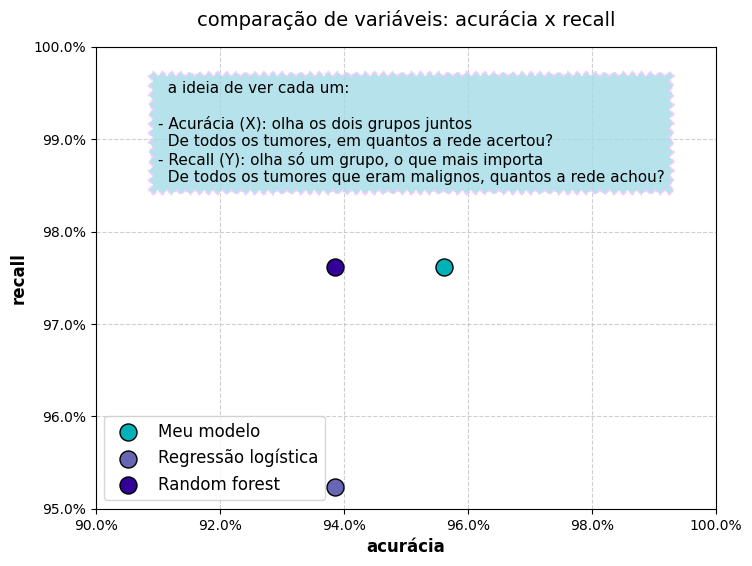

In [40]:
# resumo das comparacoes:
from sklearn.metrics import confusion_matrix

print("\n\n\033[33mComparação no teste (114 tumores)\033[0m\n")
print(f"\033[31mBaseline (sempre benigno):\033[0m acurácia {baseline_percentual:.3f} %  recall 0.000")  # corrigido
print(f"\033[31mMinha rede do zero:\033[0m        acurácia \033[32m{acuracia_teste_percentual:.3f} %\033[0m    recall \033[32m{recall_maligno_percentual:.3f} %\033[0m")  # corrigido
print(f"\033[31mRegressão logística:\033[0m       acurácia {acuracia_logistic:.3f} %    recall {recall_logistic:.3f} %")
print(f"\033[31mRandom forest:\033[0m             acurácia {acuracia_florest:.3f} %    recall {recall_florest:.3f} %\n\n\n")


# vou so montar um grafico para melhor visualizacao
import matplotlib.ticker as mticker

meu_modelo =   acuracia_teste_percentual,recall_maligno_percentual  # corrigido
regressao_log =   acuracia_logistic, recall_logistic
ramdom_frst =   acuracia_florest,recall_florest

fig, ax = plt.subplots(figsize=(8, 6))


ax.scatter(meu_modelo[0], meu_modelo[1], color='#00b1b7',s=150, edgecolor='black',label='Meu modelo', zorder=3)
ax.text(meu_modelo[0] + 0.1, meu_modelo[1] + 0.1, '', fontsize=10, fontweight='bold')

ax.scatter(regressao_log[0], regressao_log[1], color='#6666b2',s=150, edgecolor='black', label='Regressão logística', zorder=3)
ax.text(regressao_log[0] + 0.1, regressao_log[1] + 0.1, '', fontsize=10, fontweight='bold')
ax.scatter(ramdom_frst[0], ramdom_frst[1], color='#330099',s=150, edgecolor='black',label='Random forest', zorder=3)
ax.text(ramdom_frst[0] + 0.1, ramdom_frst[1] + 0.1, '', fontsize=10, fontweight='bold')


ax.set_xlabel('acurácia', fontsize=12, fontweight='bold')
ax.set_ylabel('recall', fontsize=12, fontweight='bold')
ax.set_title('comparação de variáveis: acurácia x recall', fontsize=14, pad=15)


ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))

# ajustando os limites aqui
ax.set_xlim(90, 100)  # Eixo X: 90% a 100%
ax.set_ylim(95, 100)  # Eixo Y: 95% a 100%


# colocando uma obs para quem não entende sobre
texto_obs = (
    "  a ideia de ver cada um: \n\n"
    "- Acurácia (X): olha os dois grupos juntos\n"
    "  De todos os tumores, em quantos a rede acertou? \n"
    "- Recall (Y): olha só um grupo, o que mais importa\n"
    "  De todos os tumores que eram malignos, quantos a rede achou?"
)
ax.text(
    91, 98.5, texto_obs,        # posição x e y onde o texto vai começar
    fontsize=11,
    verticalalignment='bottom',
    horizontalalignment='left',
    bbox=dict(
        boxstyle='sawtooth,pad=0.6',
        facecolor='#a4dbe8',
        edgecolor='#f1c9fe',
        linewidth= 1.5,
        linestyle='--',
        alpha=0.8
    )
)
# voltando para op grafico em si
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='lower left', fontsize=12)

plt.savefig("grafico_comparacao.png",dpi=150,bbox_inches="tight")
plt.show()